In [ ]:
! pip install langchain langchain-openai langchain-community langgraph python-dotenv faiss-cpu pypdf

  Using cached faiss_cpu-1.13.2-cp310-abi3-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (7.6 kB)
Using cached faiss_cpu-1.13.2-cp310-abi3-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (23.8 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 338.8/338.8 kB 970.7 kB/s eta 0:00:000:0100:01m


In [18]:
# pip install langchain-text-splitters
# !pip install pypdf
!pip install faiss-gpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.0/137.0 MB 2.7 MB/s  0:00:54m0:00:0100:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 581.2/581.2 MB 3.6 MB/s  0:04:21m0:00:0100:05m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 2.6 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.3/68.3 MB 2.6 MB/s  0:00:26m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.6/89.6 MB 1.3 MB/s  0:00:51m0:00:0100:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [faiss-gpu]/5 [faiss-gpu]las-cu12]u12]2]


In [3]:
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from dotenv import load_dotenv
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START
from typing import Annotated, TypedDict
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage, BaseMessage
from langgraph.prebuilt import ToolNode, tools_condition

/tmp/ipykernel_74614/2220308210.py:3: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


In [4]:
load_dotenv()

True

In [5]:
llm = ChatOpenAI(model= "gpt-4o-mini")

In [11]:
loader = PyPDFLoader("/home/tacktile-systems/LangGraph-Tutorial/Introduction to Machine Learning with Python ( PDFDrive.com )-min.pdf")
docs = loader.load()

In [12]:
docs[0].page_content[:500]

'Andreas C. Müller & Sarah Guido\nIntroduction to \nMachine \nLearning  \nwith P y thon   \nA GUIDE FOR DATA SCIENTISTS'

In [13]:
len(docs)

392

In [14]:
splitter = RecursiveCharacterTextSplitter(chunk_size= 1000, chunk_overlap= 200)
chunks = splitter.split_documents(docs)

In [15]:
len(chunks)

973

In [19]:
embeddings = OpenAIEmbeddings(model = 'text-embedding-3-small')
vector_store = FAISS.from_documents(chunks, embeddings)

In [20]:
vector_store

In [21]:
retriever = vector_store.as_retriever(search_type= 'mmr', search_kwargs= {'k':4})

In [22]:
retriever.invoke("How to create Invoice?")[0].page_content[:200]

'bases, like SQL, Excel files, and comma-separated values (CSV) files. Going into\ndetail about the functionality of pandas is out of the scope of this book. However,\nPython for Data Analysis  by Wes Mc'

In [23]:
@tool
def rag_tool(query):
    """
    Retrieves relevant information from a pdf document.
    Use this tool when use ask factual/conceptual questions that might be answered from tored documents.
    """

    result = retriever.invoke(query)

    context = [doc.page_content for doc in result]
    metadata = [doc.metadata for doc in result]

    return {'query': query, 'context': context, 'metadata': metadata}

In [24]:
tools = [rag_tool]
llm_with_tools = llm.bind_tools(tools)

In [25]:
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [26]:
def chat_node(state: ChatState):
    messages = state['messages']
    response = llm_with_tools.invoke(messages)

    return {'messages': [response]}

In [27]:
tool_node = ToolNode(tools= tools)

In [28]:
graph = StateGraph(ChatState)
graph.add_node('chat_node', chat_node)
graph.add_node('tools', tool_node)

graph.add_edge(START, 'chat_node')
graph.add_conditional_edges('chat_node', tools_condition)
graph.add_edge('tools', 'chat_node')

chatbot = graph.compile()

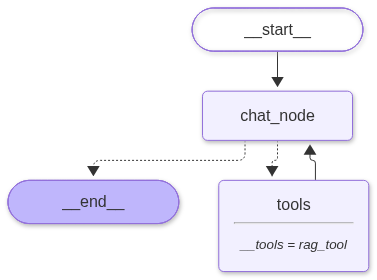

In [29]:
chatbot

In [ ]:
final_result = chatbot.invoke({
    'messages': [
        HumanMessage(
            content= "What is logg loss in Logistic regression"
            )
        ]
    })
print(final_result['messages'][-1].content)

Log loss, or logistic loss, is a performance metric for evaluating the effectiveness of a logistic regression model. It measures the difference between the actual labels and the predicted probabilities generated by the model. The log loss quantifies how well the predicted probabilities match the actual outcomes, taking into account the uncertainty of the predictions.

The formula for log loss is given by:

\[
\text{Log Loss} = -\frac{1}{N} \sum_{i=1}^{N} \left[ y_i \log(p_i) + (1 - y_i) \log(1 - p_i) \right]
\]

Where:
- \( N \) is the number of samples
- \( y_i \) is the actual label (0 or 1) for the \( i^{th} \) sample
- \( p_i \) is the predicted probability that \( y_i \) is 1

Key points about log loss:
- The value of log loss ranges from 0 to infinity. A lower log loss value indicates a better fitting model.
- Log loss penalizes incorrect predictions, especially those that are made with high confidence.
- It is particularly useful for binary classification problems where the outp